# CSC_51054_EP - Deep Learning -- Optimization and Hyperparameter Tuning

# Part 1: Adam vs SGD - Understanding Modern Optimizers

## Learning Objectives

In this lab, you will:

1. **Implement Adam and SGD optimizers from scratch** - Understanding the math behind optimization algorithms
2. **Understand when and why Adam outperforms SGD** through three key scenarios:
   - Sparse gradients (many zero features)
   - Ill-conditioned optimization landscapes (different curvatures)
   - Robust performance without careful hyperparameter tuning
3. **Visualize and measure convergence speed differences** - See the optimization race in real-time!

## Theory Overview

### What is Optimization?

In machine learning, we want to minimize a loss function by adjusting model parameters. Think of it like finding the lowest point in a valley while blindfolded - you can only feel the slope beneath your feet (the gradient).



First, we'll import NumPy and define basic building blocks for our neural network.


In [ ]:
import numpy as np

# Utility functions for neural network

def sigmoid(x):
    """Numerically-stable sigmoid activation"""
    x = np.clip(x, -40.0, 40.0)
    return 1.0 / (1.0 + np.exp(-x))

def relu(x):
    """ReLU activation: max(0, x)"""
    return np.maximum(0.0, x)

def relu_grad(x):
    """Derivative of ReLU: 1 where x>0 else 0"""
    return (x > 0).astype(x.dtype)

def binary_cross_entropy_with_logits(logits, targets, eps=1e-8):
    """
    Binary cross-entropy loss with logits.

    Args:
        logits: (N, 1) real-valued scores before sigmoid
        targets: (N, 1) in {0,1}

    Returns:
        loss: scalar float
        probs: predicted probabilities
    """
    probs = sigmoid(logits)
    probs = np.clip(probs, eps, 1.0 - eps)
    loss = -np.mean(targets * np.log(probs) + (1 - targets) * np.log(1 - probs))
    return loss, probs

def accuracy_from_logits(logits, targets):
    """Calculate accuracy from logits"""
    preds = (sigmoid(logits) >= 0.5).astype(np.float32)
    return float(np.mean(preds == targets))

print("✓ Utility functions loaded!")


✓ Utility functions loaded!


## 1.1: SGD (Stochastic Gradient Descent)

**The Classic Approach:**
```
θ_new = θ_old - learning_rate × gradient
```

SGD is the classic optimization algorithm. It updates parameters by moving in the opposite direction of the gradient.

**Update Rule:**
```
gradient = gradient + weight_decay * θ
velocity = momentum × velocity + gradient
θ = θ - learning_rate × velocity
```


### Question:

 The SGD uses a fixed learning rate for all parameters, what's the problem? Explain what is weight decay and momentum.

### Answer:

In [ ]:
class SGD:
    """
    Vanilla Stochastic Gradient Descent with optional momentum.

    Parameters:
        lr: Learning rate (default 1e-2)
        momentum: Momentum factor (default 0.0)
        weight_decay: L2 weight decay (default 0.0)
    """

    def __init__(self, lr=1e-2, momentum=0.0, weight_decay=0.0):
        self.lr = lr
        self.momentum = momentum
        self.weight_decay = weight_decay
        self.velocity = {}

    def step(self, params, grads):
        """
        One SGD update step (in-place).

        Algorithm:
            v_t = momentum × v_{t-1} + g_t
            θ_t = θ_{t-1} - lr × v_t
        """
        for k in params.keys():
            g = grads[k]

            # Apply weight decay
            if self.weight_decay > 0.0:
                g = g + self.weight_decay * params[k]

            # Lazy init velocity
            if k not in self.velocity:
                self.velocity[k] = np.zeros_like(g)

            # Update velocity with momentum
            self.velocity[k] = self.momentum * self.velocity[k] + g

            # Update parameter
            params[k] -= self.lr * self.velocity[k]


## 1.2: Adam (Adaptive Moment Estimation)

Adam is a modern optimizer that adapts the learning rate for **each parameter individually**.

**Update Rule:**
```
gradient = gradient + weight_decay * θ
m_t = β₁ × m_{t-1} + (1-β₁) × gradient        # First moment (momentum)
v_t = β₂ × v_{t-1} + (1-β₂) × gradient²       # Second moment (variance)
m̂_t = m_t / (1 - β₁^t)                         # Bias correction
v̂_t = v_t / (1 - β₂^t)                         # Bias correction
θ = θ - α × m̂_t / (√v̂_t + ε)                  # Adaptive update
```

**Key Innovations:**
- **Per-parameter learning rates**: Each weight gets its own adaptive step size
- **First moment (m)**: Exponential moving average of gradients (like momentum)
- **Second moment (v)**: Exponential moving average of squared gradients (like RMSprop)
- **Bias correction**: Compensates for initialization bias in early steps


### Question:
Explain why Adam is better than SGD.

### Answer:

- Parameters with large/frequent gradients → smaller effective learning rate
- Parameters with small/rare gradients → larger effective learning rate



In [ ]:
class Adam:
    """
    Adam optimizer with adaptive per-parameter learning rates.

    Parameters:
        lr: Learning rate (α in the paper, default 1e-3)
        beta1: Exponential decay rate for first moment (default 0.9)
        beta2: Exponential decay rate for second moment (default 0.999)
        eps: Small number for numerical stability (default 1e-8)
        weight_decay: L2 weight decay (default 0.0)
    """

    def __init__(self, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8, weight_decay=0.0):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.weight_decay = weight_decay

        self.m = {}  # First moment
        self.v = {}  # Second moment
        self.t = 0   # Time step

    def step(self, params, grads):
        """
        One Adam update step (in-place).

        Algorithm:
            m_t = β₁ × m_{t-1} + (1-β₁) × g_t
            v_t = β₂ × v_{t-1} + (1-β₂) × g_t²
            m̂_t = m_t / (1 - β₁^t)
            v̂_t = v_t / (1 - β₂^t)
            θ_t = θ_{t-1} - α × m̂_t / (√v̂_t + ε)
        """
        self.t += 1  # Increment time step
        b1, b2, lr, eps = self.beta1, self.beta2, self.lr, self.eps

        for k in params.keys():
            g = grads[k]

            # Lazy init moment buffers
            if k not in self.m:
                self.m[k] = np.zeros_like(g)
                self.v[k] = np.zeros_like(g)

            if self.weight_decay > 0.0:
              g = g + self.weight_decay * params[k]
            # Update biased first moment estimate
            self.m[k] = b1 * self.m[k] + (1.0 - b1) * g

            # Update biased second raw moment estimate
            self.v[k] = b2 * self.v[k] + (1.0 - b2) * (g * g)

            # Compute bias-corrected moments
            m_hat = self.m[k] / (1.0 - (b1 ** self.t))
            v_hat = self.v[k] / (1.0 - (b2 ** self.t))

            # Parameter update (adaptive learning rate!)
            params[k] -= lr * m_hat / (np.sqrt(v_hat) + eps)



## 1.3 test and compare the optimziers

We'll use a simple 2-layer MLP (Multi-Layer Perceptron) for binary classification.

**Architecture:**
```
Input (D features) → Linear → ReLU → Linear → Output (1 logit)
```


In [ ]:
class TinyMLP:
    """
    A minimal 2-layer MLP for binary classification.

    Architecture:
        Input -> Linear -> ReLU -> Linear -> Logit

    Shapes:
        X: (N, D)
        W1: (D, H), b1: (1, H)
        W2: (H, 1), b2: (1, 1)
    """

    def __init__(self, input_dim, hidden_dim=32, seed=42):
        rng = np.random.default_rng(seed)
        # He initialization for ReLU
        self.params = {
            "W1": rng.normal(0, np.sqrt(2.0 / input_dim), size=(input_dim, hidden_dim)),
            "b1": np.zeros((1, hidden_dim)),
            "W2": rng.normal(0, np.sqrt(2.0 / hidden_dim), size=(hidden_dim, 1)),
            "b2": np.zeros((1, 1)),
        }

    def forward(self, X):
        """Forward pass: returns logits and a cache for backprop"""
        W1, b1 = self.params["W1"], self.params["b1"]
        W2, b2 = self.params["W2"], self.params["b2"]

        z1 = X @ W1 + b1      # (N, H)
        a1 = relu(z1)         # (N, H)
        logits = a1 @ W2 + b2 # (N, 1)

        cache = {"X": X, "z1": z1, "a1": a1, "logits": logits}
        return logits, cache

    def backward(self, cache, targets):
        """
        Backpropagation through BCE-with-logits + linear layers + ReLU.
        Returns gradient dict matching self.params.
        """
        X, z1, a1, logits = cache["X"], cache["z1"], cache["a1"], cache["logits"]
        N = X.shape[0]

        # dL/dlogits for BCE-with-sigmoid
        probs = sigmoid(logits)
        dlogits = (probs - targets) / N  # (N, 1)

        # Gradients for second linear layer
        dW2 = a1.T @ dlogits
        db2 = np.sum(dlogits, axis=0, keepdims=True)

        # Backprop to hidden activations
        da1 = dlogits @ self.params["W2"].T

        # Through ReLU
        dz1 = da1 * relu_grad(z1)

        # Gradients for first linear layer
        dW1 = X.T @ dz1
        db1 = np.sum(dz1, axis=0, keepdims=True)

        return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}




We'll create three different datasets to showcase different optimization challenges:

1. **Simple Blobs**: Baseline problem
2. **Sparse Features**: 90% of features are zero
3. **Pathological Curvature**: Ill-conditioned landscape

In [ ]:
def make_blobs(n_per_class=200, distance=2.0, std=0.9, seed=0):
    """Create two Gaussian blobs in 2D"""
    rng = np.random.default_rng(seed)
    c0 = np.array([-distance/2, 0.0])
    c1 = np.array([+distance/2, 0.0])

    X0 = rng.normal(loc=c0, scale=std, size=(n_per_class, 2))
    X1 = rng.normal(loc=c1, scale=std, size=(n_per_class, 2))

    X = np.vstack([X0, X1])
    y = np.vstack([np.zeros((n_per_class, 1)), np.ones((n_per_class, 1))])

    # Shuffle
    idx = rng.permutation(len(X))
    return X[idx], y[idx]

def make_sparse_features(n_samples=400, n_features=50, sparsity=0.9, seed=0):
    """
    Create dataset with sparse features (many zeros).
    Showcases Adam's advantage with per-parameter learning rates.
    """
    rng = np.random.default_rng(seed)

    # Generate dense features first
    X = rng.normal(0, 1.0, size=(n_samples, n_features))

    # Make them sparse: randomly zero out 'sparsity' fraction
    mask = rng.random(size=(n_samples, n_features)) < sparsity
    X[mask] = 0.0

    # Create labels based on sparse linear combination
    true_weights = np.zeros(n_features)
    important_idx = rng.choice(n_features, size=5, replace=False)
    true_weights[important_idx] = rng.normal(0, 2.0, size=5)

    logits = X @ true_weights + rng.normal(0, 0.5, size=n_samples)
    y = (logits > 0).astype(np.float32).reshape(-1, 1)

    return X, y

def make_pathological_curvature(n_per_class=200, seed=0):
    """
    Create dataset with ill-conditioned landscape (different curvatures).
    SGD struggles with fixed LR; Adam adapts better.
    """
    rng = np.random.default_rng(seed)

    # Class 0: elongated along x-axis
    X0 = rng.normal(0, 1.0, size=(n_per_class, 2))
    X0[:, 0] *= 5.0  # stretch x
    X0[:, 1] *= 0.5  # shrink y
    X0[:, 0] -= 3.0

    # Class 1: elongated along y-axis
    X1 = rng.normal(0, 1.0, size=(n_per_class, 2))
    X1[:, 0] *= 0.5  # shrink x
    X1[:, 1] *= 5.0  # stretch y
    X1[:, 0] += 3.0

    X = np.vstack([X0, X1])
    y = np.vstack([np.zeros((n_per_class, 1)), np.ones((n_per_class, 1))])

    # Shuffle
    idx = rng.permutation(len(X))
    return X[idx], y[idx]



Now we'll create a function to train TWO identical models side-by-side:
- Same initialization (same random seed)
- Same architecture (same hidden_dim)
- **Only difference: optimizer choice**

In [ ]:
def compare_optimizers(X, y, epochs=500, hidden_dim=16, seed=123,
                       adam_lr=1e-2, sgd_lr=1e-2, verbose=True):
    """
    Train two identical models with Adam and SGD, return training history.
    """
    N, D = X.shape

    # Create two models with identical initialization
    model_adam = TinyMLP(input_dim=D, hidden_dim=hidden_dim, seed=seed)
    model_sgd = TinyMLP(input_dim=D, hidden_dim=hidden_dim, seed=seed)

    # Verify they start the same
    assert np.allclose(model_adam.params["W1"], model_sgd.params["W1"])

    # Optimizers
    opt_adam = Adam(lr=adam_lr, beta1=0.9, beta2=0.999, eps=1e-8)
    opt_sgd = SGD(lr=sgd_lr, momentum=0.9)

    # Training history
    history = {
        "adam_loss": [], "adam_acc": [],
        "sgd_loss": [], "sgd_acc": []
    }

    for epoch in range(1, epochs + 1):
        # --- ADAM ---
        logits_adam, cache_adam = model_adam.forward(X)
        loss_adam, _ = binary_cross_entropy_with_logits(logits_adam, y)
        acc_adam = accuracy_from_logits(logits_adam, y)
        grads_adam = model_adam.backward(cache_adam, y)
        opt_adam.step(model_adam.params, grads_adam)

        # --- SGD ---
        logits_sgd, cache_sgd = model_sgd.forward(X)
        loss_sgd, _ = binary_cross_entropy_with_logits(logits_sgd, y)
        acc_sgd = accuracy_from_logits(logits_sgd, y)
        grads_sgd = model_sgd.backward(cache_sgd, y)
        opt_sgd.step(model_sgd.params, grads_sgd)

        # Record
        history["adam_loss"].append(loss_adam)
        history["adam_acc"].append(acc_adam)
        history["sgd_loss"].append(loss_sgd)
        history["sgd_acc"].append(acc_sgd)

        # Print progress every 10 epochs
        if verbose and (epoch % 10 == 0 or epoch == 1):
            print(f"  Epoch {epoch:3d} | Adam: loss={loss_adam:.4f}, acc={acc_adam*100:5.1f}% | SGD: loss={loss_sgd:.4f}, acc={acc_sgd*100:5.1f}%")

    return history



Now we'll run three experiments to see when and why Adam outperforms SGD.

### Experiment 1: Sparse Features

**The Challenge:** 90% of features are zero - most parameters get very rare gradient updates.


In [ ]:
print("\n" + "="*60)
print("EXPERIMENT 1: Sparse Features (90% zeros)")
print("="*60)

X, y = make_sparse_features(n_samples=400, n_features=50, sparsity=0.9, seed=42)
print(f"Dataset shape: X={X.shape}, y={y.shape}")
print(f"Sparsity: {np.mean(X == 0)*100:.1f}% of features are zero\n")

history1 = compare_optimizers(X, y, epochs=500, hidden_dim=32, seed=42)

# Show final results
adam_final = history1["adam_loss"][-1]
sgd_final = history1["sgd_loss"][-1]
print(f"\n✓ Final losses: Adam={adam_final:.4f}, SGD={sgd_final:.4f}")

# Convergence speed
threshold = 0.3
adam_converge = next((i+1 for i, loss in enumerate(history1["adam_loss"]) if loss < threshold), 500)
sgd_converge = next((i+1 for i, loss in enumerate(history1["sgd_loss"]) if loss < threshold), 500)
speedup = sgd_converge / adam_converge if adam_converge < sgd_converge else 1.0
print(f"✓ Convergence speed: Adam={adam_converge} epochs, SGD={sgd_converge} epochs")
print(f"✓ Adam is {speedup:.1f}x faster! 🚀")



EXPERIMENT 1: Sparse Features (90% zeros)
Dataset shape: X=(400, 50), y=(400, 1)
Sparsity: 90.1% of features are zero

  Epoch   1 | Adam: loss=0.7298, acc= 46.5% | SGD: loss=0.7298, acc= 46.5%
  Epoch  10 | Adam: loss=0.5643, acc= 70.5% | SGD: loss=0.7139, acc= 50.5%
  Epoch  20 | Adam: loss=0.4429, acc= 80.5% | SGD: loss=0.6913, acc= 54.0%
  Epoch  30 | Adam: loss=0.3453, acc= 85.0% | SGD: loss=0.6772, acc= 56.8%
  Epoch  40 | Adam: loss=0.2644, acc= 91.0% | SGD: loss=0.6674, acc= 60.0%
  Epoch  50 | Adam: loss=0.2010, acc= 95.0% | SGD: loss=0.6585, acc= 61.3%
  Epoch  60 | Adam: loss=0.1539, acc= 96.2% | SGD: loss=0.6499, acc= 62.3%
  Epoch  70 | Adam: loss=0.1204, acc= 96.5% | SGD: loss=0.6416, acc= 63.0%
  Epoch  80 | Adam: loss=0.0966, acc= 97.0% | SGD: loss=0.6336, acc= 63.7%
  Epoch  90 | Adam: loss=0.0796, acc= 98.0% | SGD: loss=0.6258, acc= 64.0%
  Epoch 100 | Adam: loss=0.0671, acc= 98.5% | SGD: loss=0.6181, acc= 65.8%
  Epoch 110 | Adam: loss=0.0577, acc= 98.8% | SGD: loss

### Question:
Why Adam works better in this case?

### Answer:

- SGD uses the same learning rate for all parameters → rarely-updated params make slow progress
- Adam tracks per-parameter statistics → rare params get larger effective learning rates when they do update


### Experiment 2: Pathological Curvature

**The Challenge:** Loss landscape has very different curvatures in different directions - like a narrow valley.

In [ ]:
print("\n" + "="*60)
print("EXPERIMENT 2: Pathological Curvature (Ill-conditioned)")
print("="*60)

X, y = make_pathological_curvature(n_per_class=300, seed=42)
print(f"Dataset shape: X={X.shape}, y={y.shape}")
print(f"Feature variance: X[:, 0]={np.var(X[:, 0]):.2f}, X[:, 1]={np.var(X[:, 1]):.2f}")
print("(Notice the large difference in variance - this is ill-conditioned!)\n")

history2 = compare_optimizers(X, y, epochs=500, hidden_dim=32, seed=42)

# Show final results
adam_final = history2["adam_loss"][-1]
sgd_final = history2["sgd_loss"][-1]
adam_acc_final = history2["adam_acc"][-1]
sgd_acc_final = history2["sgd_acc"][-1]
print(f"\n✓ Final results: Adam: loss={adam_final:.4f}, acc={adam_acc_final*100:.1f}%")
print(f"                 SGD:  loss={sgd_final:.4f}, acc={sgd_acc_final*100:.1f}%")

# Convergence speed
threshold = 0.3
adam_converge = next((i+1 for i, loss in enumerate(history2["adam_loss"]) if loss < threshold), 500)
sgd_converge = next((i+1 for i, loss in enumerate(history2["sgd_loss"]) if loss < threshold), 500)
print(f"✓ Epochs to reach loss < 0.3: Adam={adam_converge}, SGD={sgd_converge}")



EXPERIMENT 2: Pathological Curvature (Ill-conditioned)
Dataset shape: X=(600, 2), y=(600, 1)
Feature variance: X[:, 0]=21.81, X[:, 1]=13.05
(Notice the large difference in variance - this is ill-conditioned!)

  Epoch   1 | Adam: loss=2.9690, acc= 14.3% | SGD: loss=2.9690, acc= 14.3%
  Epoch  10 | Adam: loss=0.3664, acc= 86.5% | SGD: loss=0.8632, acc= 86.5%
  Epoch  20 | Adam: loss=0.4052, acc= 86.5% | SGD: loss=0.4184, acc= 86.5%
  Epoch  30 | Adam: loss=0.3026, acc= 86.5% | SGD: loss=0.2874, acc= 83.8%
  Epoch  40 | Adam: loss=0.2354, acc= 88.3% | SGD: loss=0.2383, acc= 86.8%
  Epoch  50 | Adam: loss=0.2293, acc= 90.8% | SGD: loss=0.2103, acc= 88.2%
  Epoch  60 | Adam: loss=0.2104, acc= 89.0% | SGD: loss=0.1974, acc= 88.2%
  Epoch  70 | Adam: loss=0.2018, acc= 89.2% | SGD: loss=0.1915, acc= 89.2%
  Epoch  80 | Adam: loss=0.1923, acc= 90.3% | SGD: loss=0.1885, acc= 88.5%
  Epoch  90 | Adam: loss=0.1844, acc= 91.3% | SGD: loss=0.1865, acc= 88.8%
  Epoch 100 | Adam: loss=0.1767, acc= 9

### Experiment 3: Simple Gaussian Blobs (Baseline)

**The Challenge:** Well-separated Gaussian clusters - this is an "easy" problem.

**Expected Result:** Both optimizers should work reasonably well here.

This shows that Adam is a robust default choice - it doesn't hurt performance on easy problems!


In [ ]:
print("\n" + "="*60)
print("EXPERIMENT 3: Simple Gaussian Blobs (Easy Problem)")
print("="*60)

X, y = make_blobs(n_per_class=300, distance=3.0, std=1.0, seed=42)
print(f"Dataset shape: X={X.shape}, y={y.shape}")
print("This is a simple, well-separated 2D classification problem.\n")

history3 = compare_optimizers(X, y, epochs=300, hidden_dim=32, seed=42)

# Show final results
adam_final = history3["adam_loss"][-1]
sgd_final = history3["sgd_loss"][-1]
adam_acc_final = history3["adam_acc"][-1]
sgd_acc_final = history3["sgd_acc"][-1]
print(f"\n✓ Final results: Adam: loss={adam_final:.4f}, acc={adam_acc_final*100:.1f}%")
print(f"                 SGD:  loss={sgd_final:.4f}, acc={sgd_acc_final*100:.1f}%")



EXPERIMENT 3: Simple Gaussian Blobs (Easy Problem)
Dataset shape: X=(600, 2), y=(600, 1)
This is a simple, well-separated 2D classification problem.

  Epoch   1 | Adam: loss=1.3665, acc= 16.5% | SGD: loss=1.3665, acc= 16.5%
  Epoch  10 | Adam: loss=0.4022, acc= 93.0% | SGD: loss=0.2545, acc= 93.5%
  Epoch  20 | Adam: loss=0.1943, acc= 93.8% | SGD: loss=0.1634, acc= 93.7%
  Epoch  30 | Adam: loss=0.1601, acc= 93.7% | SGD: loss=0.1590, acc= 93.8%
  Epoch  40 | Adam: loss=0.1528, acc= 93.7% | SGD: loss=0.1575, acc= 93.7%
  Epoch  50 | Adam: loss=0.1506, acc= 93.5% | SGD: loss=0.1560, acc= 93.7%
  Epoch  60 | Adam: loss=0.1494, acc= 93.5% | SGD: loss=0.1547, acc= 93.7%
  Epoch  70 | Adam: loss=0.1485, acc= 93.5% | SGD: loss=0.1536, acc= 93.7%
  Epoch  80 | Adam: loss=0.1479, acc= 93.5% | SGD: loss=0.1529, acc= 93.7%
  Epoch  90 | Adam: loss=0.1474, acc= 93.2% | SGD: loss=0.1523, acc= 93.7%
  Epoch 100 | Adam: loss=0.1469, acc= 93.2% | SGD: loss=0.1519, acc= 93.7%
  Epoch 110 | Adam: loss

Visualization (Optional)

Let's visualize the training curves to see the difference more clearly!


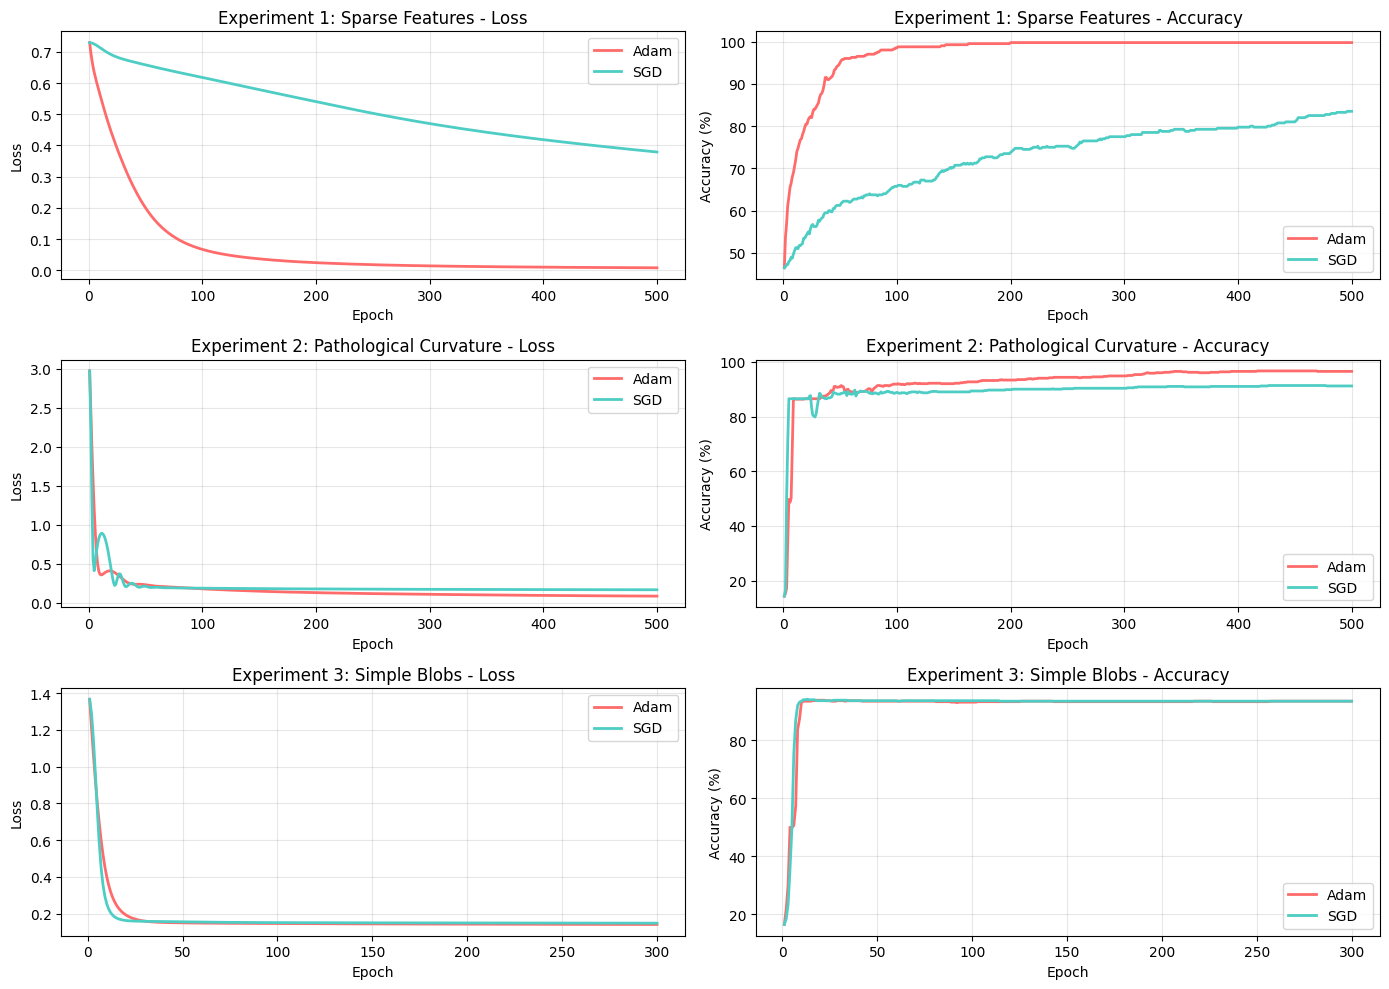

✓ Visualization complete!


In [ ]:
try:
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(3, 2, figsize=(14, 10))

    scenarios = [
        (history1, "Experiment 1: Sparse Features", 500),
        (history2, "Experiment 2: Pathological Curvature", 500),
        (history3, "Experiment 3: Simple Blobs", 300)
    ]

    for i, (history, title, epochs) in enumerate(scenarios):
        # Loss plot
        axes[i, 0].plot(range(1, epochs+1), history["adam_loss"],
                       label="Adam", linewidth=2, color='#FF6B6B')
        axes[i, 0].plot(range(1, epochs+1), history["sgd_loss"],
                       label="SGD", linewidth=2, color='#4ECDC4')
        axes[i, 0].set_xlabel("Epoch")
        axes[i, 0].set_ylabel("Loss")
        axes[i, 0].set_title(f"{title} - Loss")
        axes[i, 0].legend()
        axes[i, 0].grid(True, alpha=0.3)

        # Accuracy plot
        axes[i, 1].plot(range(1, epochs+1), [a*100 for a in history["adam_acc"]],
                       label="Adam", linewidth=2, color='#FF6B6B')
        axes[i, 1].plot(range(1, epochs+1), [a*100 for a in history["sgd_acc"]],
                       label="SGD", linewidth=2, color='#4ECDC4')
        axes[i, 1].set_xlabel("Epoch")
        axes[i, 1].set_ylabel("Accuracy (%)")
        axes[i, 1].set_title(f"{title} - Accuracy")
        axes[i, 1].legend()
        axes[i, 1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("✓ Visualization complete!")

except ImportError:
    print("⚠️  matplotlib not available. Install with: pip install matplotlib")


try different beta


# Part 2: Deep Learning Hyperparameter

## Overview
This part will teach you how different hyperparameters affect neural network training through hands-on experiments and visualizations.

### Learning Objectives

By the end of this tutorial, you will:
- Understand how learning rate affects convergence speed and stability
- Recognize the signs of divergence (when training becomes unstable)
- Learn the trade-offs between different batch sizes
- Apply regularization techniques to prevent overfitting

### Key Hyperparameters Explored

1. **Learning Rate (LR)**: Controls how big each gradient descent step is
2. **Batch Size**: Number of samples processed before updating weights
4. **Dropout**: Randomly disables neurons during training to improve generalization

### Question: Explain how large and small value of these hyperparameters can influence the training.

### Answer:

### Question: How to tell the trained model is good based on training/validation loss/accuracy?

### Answer:


In [ ]:
# Import libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)


In [ ]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
import torch

def make_torch_classification_data(
    n_samples=4000,
    n_features=30,
    n_informative=12,
    n_redundant=5,
    n_repeated=0,
    n_clusters_per_class=2,
    class_sep=1.0,
    flip_y=0.05,
    test_size=0.25,
    random_state=42
):
    """
    Generate a synthetic classification dataset and return PyTorch tensors.

    Returns:
        X_train, y_train, X_val, y_val (torch.FloatTensor, torch.LongTensor)
    """
    # Generate synthetic dataset
    X, y = make_classification(
        n_samples=n_samples,
        n_features=n_features,
        n_informative=n_informative,
        n_redundant=n_redundant,
        n_repeated=n_repeated,
        n_clusters_per_class=n_clusters_per_class,
        class_sep=class_sep,
        flip_y=flip_y,
        random_state=random_state
    )

    # Split into train/validation sets
    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    # Convert to PyTorch tensors
    X_train = torch.FloatTensor(X_train)
    y_train = torch.LongTensor(y_train)
    X_val = torch.FloatTensor(X_val)
    y_val = torch.LongTensor(y_val)

    # Print dataset info
    print(f"Training samples: {len(X_train)}")
    print(f"Validation samples: {len(X_val)}")
    print(f"Feature dimension: {X_train.shape[1]}")

    return X_train, y_train, X_val, y_val


## Model Architecture

In [ ]:
class SimpleNet(nn.Module):
    def __init__(self, input_dim, dropout_rate=0.0):
        super(SimpleNet, self).__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 2)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout_rate)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.fc3(x)
        return x



## Training Function


In [ ]:
def train_model(model, train_loader, val_data, criterion, optimizer, epochs=20):
    """
    Train model and return history of losses and accuracies.
    """
    history = {
        'train_loss': [],
        'val_loss': [],
        'train_acc': [],
        'val_acc': []
    }

    X_val_data, y_val_data = val_data

    for epoch in range(epochs):
        # Training phase
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            train_total += y_batch.size(0)
            train_correct += (predicted == y_batch).sum().item()

        # Validation phase
        model.eval()
        with torch.no_grad():
            val_outputs = model(X_val_data)
            val_loss = criterion(val_outputs, y_val_data).item()
            _, val_predicted = torch.max(val_outputs.data, 1)
            val_acc = (val_predicted == y_val_data).sum().item() / len(y_val_data)

        # Record metrics
        history['train_loss'].append(train_loss / len(train_loader))
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_correct / train_total)
        history['val_acc'].append(val_acc)

    return history

print("Training function ready!")

Training function ready!


## Experiment 1: Learning Rate Effects

The **learning rate** is one of the most critical hyperparameters. It controls how much we adjust weights in response to the gradient.

In [ ]:
features = 30

X_train, y_train, X_val, y_val = make_torch_classification_data(
    n_samples=4000,
    n_features=features,
    n_informative=12,
    n_redundant=5,
    n_repeated=0,
    n_clusters_per_class=2,
    class_sep=1.0,
    flip_y=0.05,
    test_size=0.25,
    random_state=42
)


Training samples: 3000
Validation samples: 1000
Feature dimension: 30


In [ ]:
# Test different learning rates
learning_rates = [0.0001, 0.001, 0.1]
lr_histories = {}

for lr in learning_rates:
    print(f"Training with learning rate: {lr}")

    # Create fresh model and optimizer
    model = SimpleNet(input_dim=features)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    # Create data loader with fixed batch size
    train_dataset = TensorDataset(X_train, y_train)
    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

    # Train model
    history = train_model(model, train_loader, (X_val, y_val),
                         criterion, optimizer, epochs=20)
    lr_histories[lr] = history


Training with learning rate: 0.0001
Training with learning rate: 0.001
Training with learning rate: 0.1


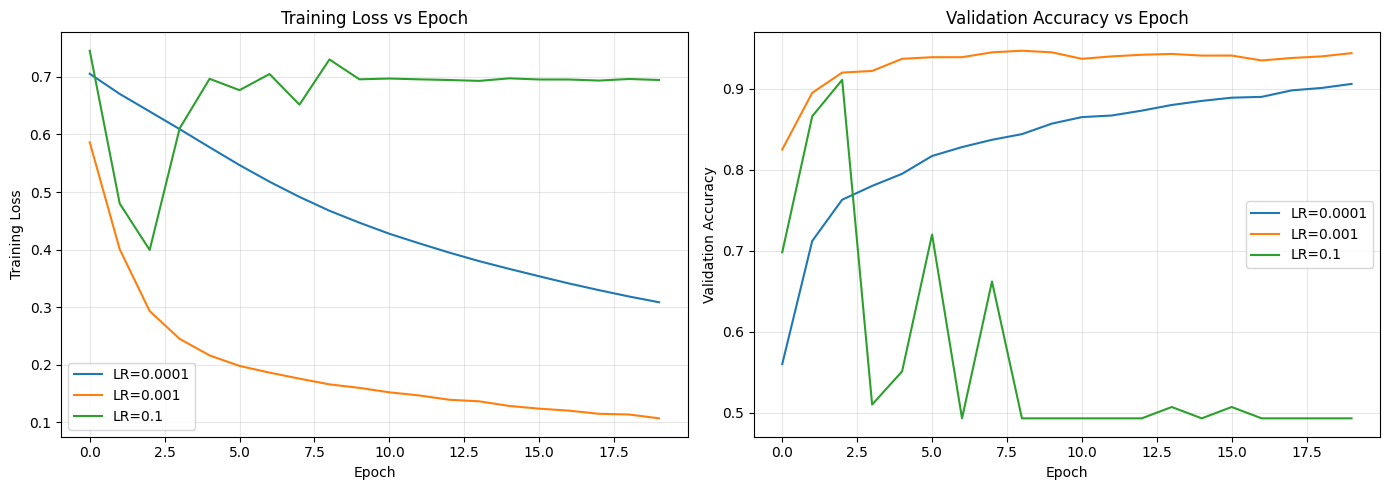

In [ ]:
# Plot learning rate comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot training loss
for lr, history in lr_histories.items():
    axes[0].plot(history['train_loss'], label=f'LR={lr}')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Training Loss')
axes[0].set_title('Training Loss vs Epoch')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot validation accuracy
for lr, history in lr_histories.items():
    axes[1].plot(history['val_acc'], label=f'LR={lr}')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Validation Accuracy')
axes[1].set_title('Validation Accuracy vs Epoch')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('learning_rate_comparison.png', dpi=100, bbox_inches='tight')
plt.show()



## Experiment 2: Batch Size Effects

**Batch size** determines how many samples are used to compute each gradient update.



In [ ]:
features = 30

X_train, y_train, X_val, y_val = make_torch_classification_data(
    n_samples=1000,
    n_features=features,
    n_informative=12,
    n_redundant=5,
    n_repeated=0,
    n_clusters_per_class=2,
    class_sep=1.0,
    flip_y=0.05,
    test_size=0.25,
    random_state=42
)


Training samples: 750
Validation samples: 250
Feature dimension: 30


In [ ]:
import time

# Test different batch sizes
batch_sizes = [1, 64, 512]
bs_histories = {}

for bs in batch_sizes:
    print(f"\nTraining with batch size: {bs}")

    # Start timer
    start_time = time.time()

    # Create fresh model and optimizer
    model = SimpleNet(input_dim=features)
    optimizer = optim.Adam(model.parameters(), lr=0.003)
    criterion = nn.CrossEntropyLoss()

    # Create data loader with different batch size
    train_dataset = TensorDataset(X_train, y_train)
    train_loader = DataLoader(train_dataset, batch_size=bs, shuffle=True)

    # Train model
    history = train_model(model, train_loader, (X_val, y_val),
                         criterion, optimizer, epochs=30)

    # Record end time
    end_time = time.time()
    elapsed = end_time - start_time
    history["time"] = elapsed

    bs_histories[bs] = history
    print(f"Batch size {bs} finished in {elapsed:.2f} seconds")

print("\nBatch size experiments completed!")



Training with batch size: 1
Batch size 1 finished in 30.96 seconds

Training with batch size: 64
Batch size 64 finished in 0.77 seconds

Training with batch size: 512
Batch size 512 finished in 0.38 seconds

Batch size experiments completed!


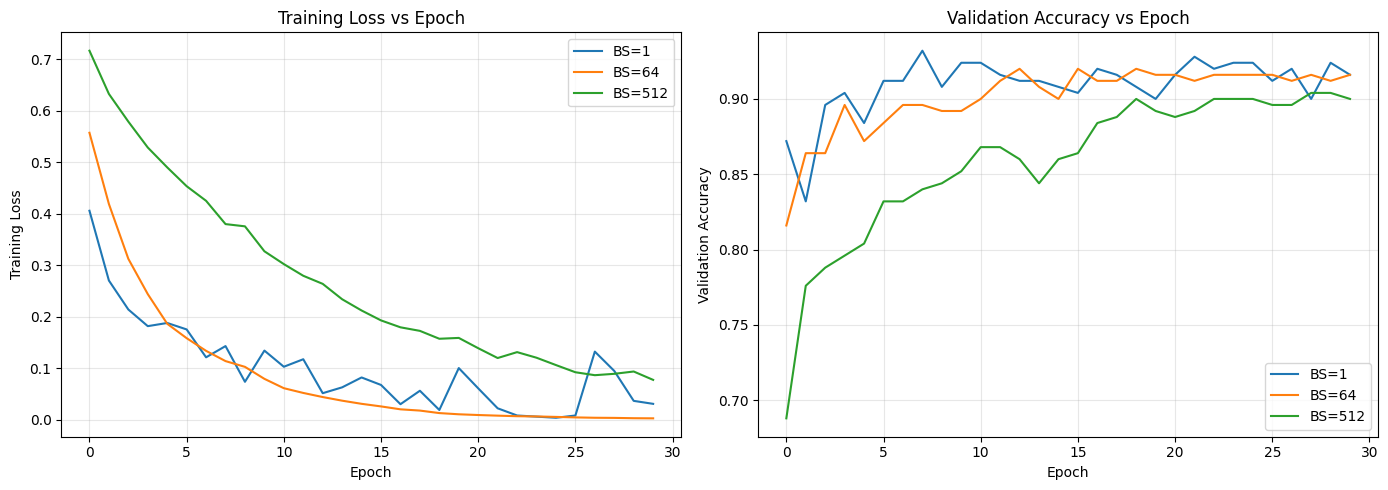

In [ ]:
# Plot batch size comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot training loss
for bs, history in bs_histories.items():
    axes[0].plot(history['train_loss'], label=f'BS={bs}')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Training Loss')
axes[0].set_title('Training Loss vs Epoch')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot validation accuracy
for bs, history in bs_histories.items():
    axes[1].plot(history['val_acc'], label=f'BS={bs}')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Validation Accuracy')
axes[1].set_title('Validation Accuracy vs Epoch')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('batch_size_comparison.png', dpi=100, bbox_inches='tight')
plt.show()



## Experiment 3: Dropout Effects

**Dropout** is a regularization technique that randomly "drops" neurons during training. This prevents the network from relying too heavily on specific neurons and improves generalization.

In [ ]:
features = 15

X_train, y_train, X_val, y_val = make_torch_classification_data(
    n_samples=1000,
    n_features=features,
    n_informative=8,
    n_redundant=3,
    n_repeated=3,
    n_clusters_per_class=2,
    class_sep=1.0,
    flip_y=0.05,
    test_size=0.5,
    random_state=42
)


Training samples: 500
Validation samples: 500
Feature dimension: 15


In [ ]:
# Test different dropout rates
dropout_rates = [0.0, 0.3, 0.5]
dropout_histories = {}

for dropout in dropout_rates:
    print(f"Training with dropout rate: {dropout}")

    # Create fresh model with dropout
    model = SimpleNet(input_dim=features, dropout_rate=dropout)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    # Create data loader
    train_dataset = TensorDataset(X_train, y_train)
    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

    # Train model
    history = train_model(model, train_loader, (X_val, y_val),
                         criterion, optimizer, epochs=60)
    dropout_histories[dropout] = history



Training with dropout rate: 0.0
Training with dropout rate: 0.3
Training with dropout rate: 0.5


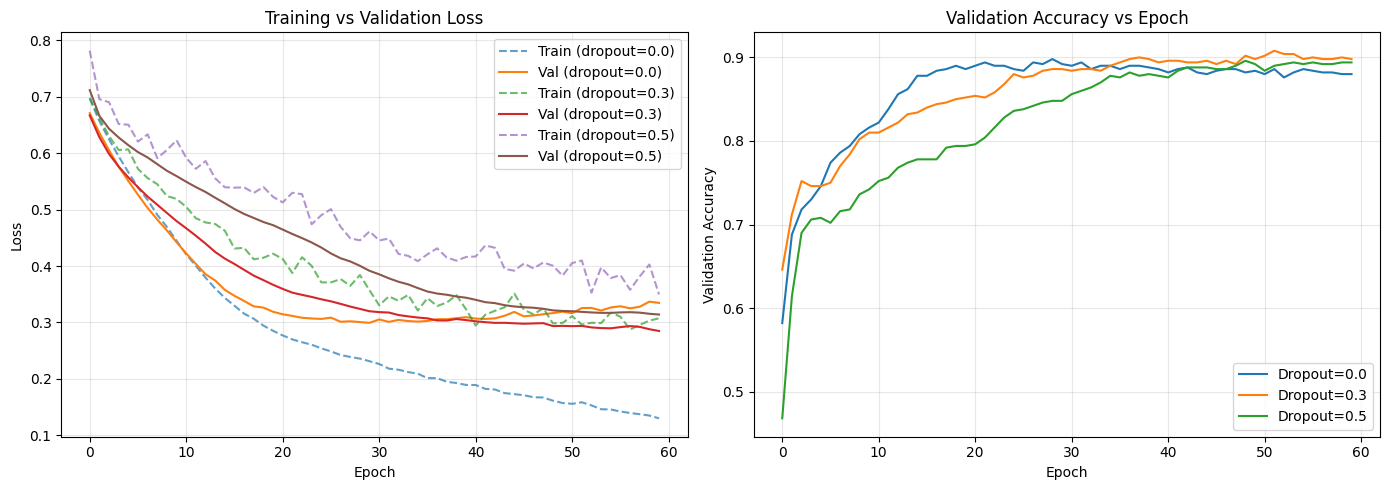

In [ ]:
# Plot dropout comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot training vs validation loss
for dropout, history in dropout_histories.items():
    axes[0].plot(history['train_loss'], linestyle='--',
                label=f'Train (dropout={dropout})', alpha=0.7)
    axes[0].plot(history['val_loss'], linestyle='-',
                label=f'Val (dropout={dropout})')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training vs Validation Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot validation accuracy
for dropout, history in dropout_histories.items():
    axes[1].plot(history['val_acc'], label=f'Dropout={dropout}')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Validation Accuracy')
axes[1].set_title('Validation Accuracy vs Epoch')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('dropout_comparison.png', dpi=100, bbox_inches='tight')
plt.show()



# Part 3: Grid Search for Hyperparameter Optimization

## Overview
This part demonstrates how to use **GridSearchCV** to automatically find the best hyperparameters for a machine learning model. Hyperparameter tuning is a critical step in building high-performance models.

### Key Concepts:

1. **Grid Search**: A systematic approach that tests all possible combinations of hyperparameters from a predefined grid
2. **Cross-Validation**: Splits training data into multiple folds to get reliable performance estimates

In [ ]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

## Generate Synthetic Dataset

In [ ]:
features = 20

X_train, y_train, X_test, y_test = make_torch_classification_data(
    n_samples=1000,
    n_features=features,
    n_informative=5,
    n_redundant=2,
    n_repeated=2,
    test_size=0.2,
    random_state=42
)


Training samples: 800
Validation samples: 200
Feature dimension: 20


## Define Model and Parameter Grid

We define a **parameter grid** containing all hyperparameter combinations to test.

GridSearch will test all combinations.

### Question: How many combinations in the following grid search?

### Answer:

In [ ]:
# Create model
model = RandomForestClassifier(random_state=42, n_jobs=-1)

# Define the grid of hyperparameters we want to search
param_grid = {
    'n_estimators': [100, 300, 500, 800],
    'max_depth': [3, 10],
    # 'min_samples_split': [2, 5, 10, 20],
    # 'min_samples_leaf': [1, 2, 5, 10],
    # 'max_features': ['sqrt', 'log2', None],
    # 'bootstrap': [True, False]
}

print("Parameter grid:")
for param, values in param_grid.items():
    print(f"  {param}: {values}")

Parameter grid:
  n_estimators: [100, 300, 500, 800]
  max_depth: [3, 10]


## Perform Grid Search with Cross-Validation

**GridSearchCV** automates the entire hyperparameter tuning process:

1. Tests all parameter combinations from the grid
2. For each combination, performs 5-fold cross-validation
3. Calculates average performance across folds
4. Selects the best performing combination
5. Retrains the model with best parameters on full training set

This is the **core of automated model optimization**!

In [ ]:
# Grid search setup
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,                 # 5-fold cross-validation
    n_jobs=-1,            # use all CPU cores
    verbose=1,            # print progress
    scoring='accuracy'    # optimize for accuracy
)

# Fit grid search on the training data
print("Starting grid search...")
grid_search.fit(X_train, y_train)
print("Grid search complete!")

Starting grid search...
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Grid search complete!


## Extract and Display Best Parameters

After testing all combinations, GridSearch identifies the winner:

- `best_params_`: The optimal hyperparameter values
- `best_score_`: Cross-validation accuracy with those parameters
- `best_estimator_`: The fully trained model ready to use


In [ ]:
print("\n" + "="*50)
print("GRID SEARCH RESULTS")
print("="*50)
print(f"\nBest Parameters: {grid_search.best_params_}")
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_ * 100:.2f}%")

# Get the best model
best_model = grid_search.best_estimator_
print(f"\nBest model: {best_model}")



GRID SEARCH RESULTS

Best Parameters: {'max_depth': 10, 'n_estimators': 100}
Best Cross-Validation Accuracy: 90.62%

Best model: RandomForestClassifier(max_depth=10, n_jobs=-1, random_state=42)


## Evaluate on the Test Set

**Critical validation step:** Test the optimized model on completely unseen data.

This reveals how well the model generalizes to new examples. The classification report provides:
- **Precision**: Of all positive predictions, how many were correct?
- **Recall**: Of all actual positives, how many did we find?
- **F1-score**: Harmonic mean of precision and recall
- **Support**: Number of samples in each class

In [ ]:
y_pred = best_model.predict(X_test)
test_acc = accuracy_score(y_test, y_pred)

print("\n" + "="*50)
print("TEST SET EVALUATION")
print("="*50)
print(f"\nTest Accuracy: {test_acc * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))



TEST SET EVALUATION

Test Accuracy: 88.50%

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.91      0.88        94
           1       0.92      0.86      0.89       106

    accuracy                           0.89       200
   macro avg       0.89      0.89      0.88       200
weighted avg       0.89      0.89      0.89       200



## Visualize Confusion Matrix

The confusion matrix shows a detailed breakdown of predictions:

- **Diagonal elements**: Correct predictions (True Positives and True Negatives)
- **Off-diagonal elements**: Misclassifications (False Positives and False Negatives)

This helps identify which classes are being confused with each other and where the model struggles.

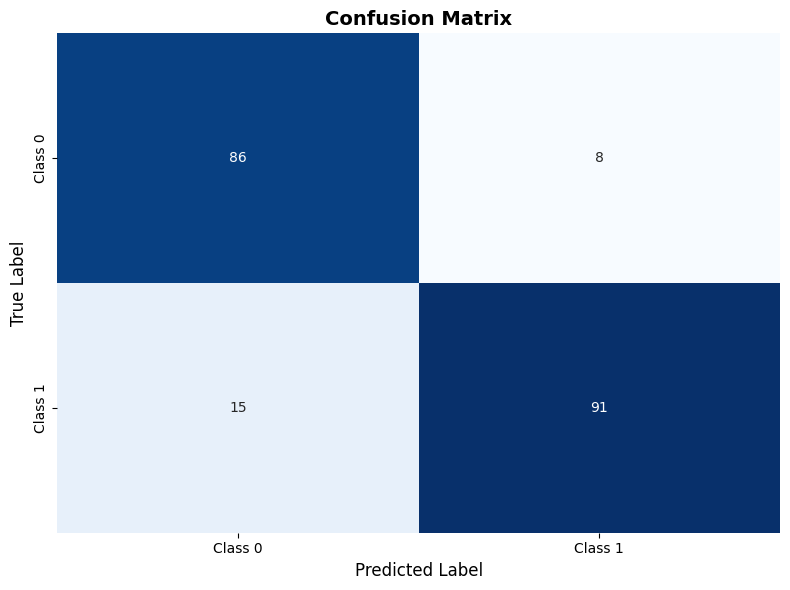


Confusion Matrix Interpretation:
True Negatives (correctly predicted Class 0): 86
False Positives (incorrectly predicted Class 1): 8
False Negatives (incorrectly predicted Class 0): 15
True Positives (correctly predicted Class 1): 91


In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'])
plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()



### Question: How to Interpret this Matirx?

### Answer:

# Part 3: Hyperparameter Tuning with Optuna and scikit-learn


## What is Optuna?
Optuna is an automatic hyperparameter optimization framework that uses intelligent search strategies to find optimal hyperparameters more efficiently than traditional grid search or random search methods.

## Key Concepts:
- **Objective Function**: A function that trains a model with given hyperparameters and returns a metric to optimize
- **Trial**: A single execution of the objective function with specific hyperparameter values
- **Study**: A complete optimization session consisting of multiple trials
- **Sampler**: The algorithm used to suggest hyperparameters (default: Tree-structured Parzen Estimator)

## Workflow:
1. Prepare data and define train/test splits
2. Define an objective function that evaluates model performance
3. Create a study and run optimization trials
4. Retrieve the best hyperparameters
5. Train the final model and evaluate on test set

### Question: Why Optuna is better than traditional grid search, what is the difference?

### Answer:

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.9/400.9 kB 7.4 MB/s eta 0:00:00


In [ ]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import cross_val_score, StratifiedKFold, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import optuna


## We use `StratifiedKFold` to maintain class proportions in each fold

In [ ]:
# Create a cross-validation splitter to reuse across trials
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## Define the Objective Function

The **objective function** is the heart of Optuna optimization. This function:
1. Receives a `trial` object from Optuna
2. Uses the trial to suggest hyperparameter values from specified ranges
3. Trains a model with those hyperparameters
4. Evaluates performance using cross-validation
5. Returns a metric that Optuna will optimize (maximize or minimize)

Optuna will intelligently explore this search space, learning from previous trials to focus on promising regions.

In [ ]:
def objective(trial: optuna.Trial) -> float:
    """
    Objective function for Optuna optimization.

    Args:
        trial: Optuna trial object that suggests hyperparameters

    Returns:
        Mean cross-validated accuracy score
    """
    # Suggest hyperparameter values for this trial
    n_estimators = trial.suggest_int("n_estimators", 100, 800)
    max_depth = trial.suggest_int("max_depth", 3, 30)
    min_samples_split = trial.suggest_int("min_samples_split", 2, 20)
    min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 10)
    max_features = trial.suggest_categorical("max_features", ["sqrt", "log2", None])
    bootstrap = trial.suggest_categorical("bootstrap", [True, False])

    # Create model with suggested hyperparameters
    clf = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        max_features=max_features,
        bootstrap=bootstrap,
        random_state=42,
        n_jobs=-1
    )

    # Evaluate using cross-validation
    scores = cross_val_score(clf, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)

    # Return mean accuracy for Optuna to maximize
    return scores.mean()


## Create and Run the Optuna Study

A **study** is Optuna's optimization session. Key parameters:
- `direction="maximize"`: We want to find hyperparameters that maximize accuracy
- `n_trials=50`: Run the objective function 50 times with different hyperparameter combinations

**How Optuna works:**
- Uses Tree-structured Parzen Estimator (TPE) algorithm by default
- Each trial informs the next, making it smarter than random search
- Balances exploration (trying diverse configurations) and exploitation (focusing on promising areas)
- The progress bar shows real-time optimization progress

In [ ]:
# Create the study
study = optuna.create_study(direction="maximize", study_name="rf_study")

# Run optimization
print("Starting hyperparameter optimization...")
study.optimize(objective, n_trials=50, show_progress_bar=True)
print("\nOptimization complete!")


[I 2025-11-03 15:20:26,573] A new study created in memory with name: rf_study


Starting hyperparameter optimization...


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2025-11-03 15:20:51,720] Trial 0 finished with value: 0.89125 and parameters: {'n_estimators': 779, 'max_depth': 23, 'min_samples_split': 9, 'min_samples_leaf': 8, 'max_features': 'log2', 'bootstrap': True}. Best is trial 0 with value: 0.89125.
[I 2025-11-03 15:20:57,432] Trial 1 finished with value: 0.8975 and parameters: {'n_estimators': 156, 'max_depth': 21, 'min_samples_split': 2, 'min_samples_leaf': 6, 'max_features': 'sqrt', 'bootstrap': False}. Best is trial 1 with value: 0.8975.
[I 2025-11-03 15:21:05,674] Trial 2 finished with value: 0.905 and parameters: {'n_estimators': 215, 'max_depth': 14, 'min_samples_split': 10, 'min_samples_leaf': 3, 'max_features': 'log2', 'bootstrap': False}. Best is trial 2 with value: 0.905.
[I 2025-11-03 15:21:14,620] Trial 3 finished with value: 0.8950000000000001 and parameters: {'n_estimators': 220, 'max_depth': 17, 'min_samples_split': 11, 'min_samples_leaf': 6, 'max_features': None, 'bootstrap': True}. Best is trial 2 with value: 0.905.
[I 

## Retrieve Best Hyperparameters and Train Final Model

After optimization completes, we:
1. Extract the best hyperparameters found by Optuna
2. Train a final model using these optimal parameters on the entire training set
3. This gives us a production-ready model with the best configuration discovered

The `study.best_trial.params` contains the hyperparameter combination that achieved the highest cross-validated accuracy.

In [ ]:
# Extract best hyperparameters
best_params = study.best_trial.params

print("Best Hyperparameters Found:")
for param, value in best_params.items():
    print(f"  {param}: {value}")

# Train final model with best hyperparameters
best_model = RandomForestClassifier(random_state=42, n_jobs=-1, **best_params)
best_model.fit(X_train, y_train)

print(f"\nBest Cross-Validated Accuracy: {study.best_value:.4f}")


Best Hyperparameters Found:
  n_estimators: 187
  max_depth: 15
  min_samples_split: 2
  min_samples_leaf: 2
  max_features: log2
  bootstrap: False

Best Cross-Validated Accuracy: 0.9163


In [ ]:
# Make predictions on test set
y_pred = best_model.predict(X_test)

# Calculate accuracy
test_accuracy = accuracy_score(y_test, y_pred)

# Display results
print("=" * 60)
print("FINAL RESULTS")
print("=" * 60)
print(f"\nBest CV Accuracy (Training): {study.best_value:.4f}")
print(f"Test Set Accuracy:           {test_accuracy:.4f}")
print(f"\nDifference: {abs(study.best_value - test_accuracy):.4f}")

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_test, y_pred))


FINAL RESULTS

Best CV Accuracy (Training): 0.9163
Test Set Accuracy:           0.9100

Difference: 0.0063

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.90      0.91      0.91        94
           1       0.92      0.91      0.91       106

    accuracy                           0.91       200
   macro avg       0.91      0.91      0.91       200
weighted avg       0.91      0.91      0.91       200



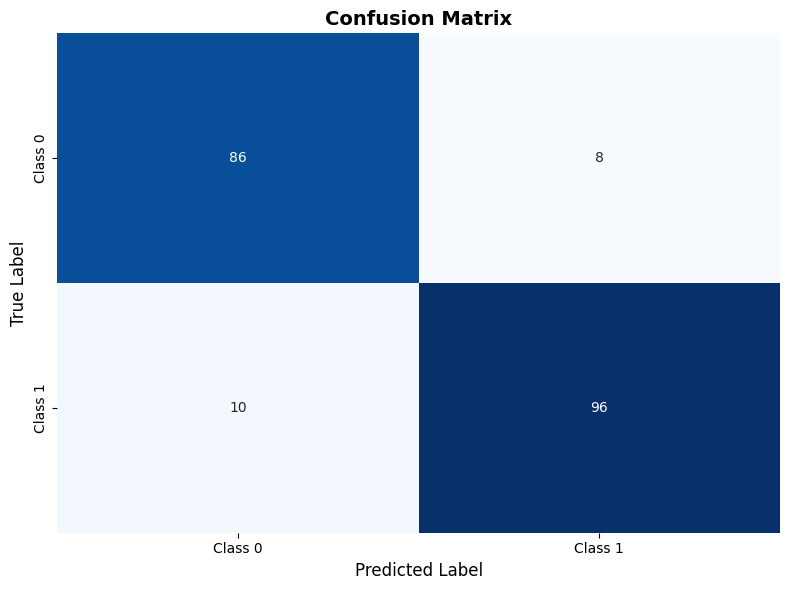

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'])
plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

